# Tarea 3 · Fritz renegocia, parte 3: el menú

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica · UNAM, Instituto de Geología · noviembre de 2026
**Entrega:** antes del martes 24 de noviembre · **Tiempo estimado:** unas 2 horas (es el trabajo asíncrono de la sesión) · **Valor:** 10 puntos (8 automáticos, 2 de interpretación)

**Para aprobar:** este cuaderno se aprueba con **6 de 10** puntos. Con **2 de los 4 cuadernos** aprobados, el examen del curso está aprobado.

---

## El problema

Fritz renegoció: ya no tiene un contrato fijo en el pozo 3, los **tres pozos** se deciden (de 0 a 500 m³/d). La autoridad le mantiene el humedal en
**1.25 m** como regla ambiental, y los pozos no pueden abatir más de 3 m. Es el problema del cuaderno de la sesión 3, el mismo para todos. Fritz quiere ver el menú completo entre dos cosas que chocan, las del cuaderno
de la sesión 3 (sección 2):

$$
\text{Costo}(\mathbf{p}) = \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big), \qquad
I(\mathbf{p}) = \sum_{i=1}^{3} \exp\bigl(-k\,[c_i^0 + a_i\,p_i]\bigr)
$$

el **costo del bombeo** ($c = 0.01, 0.015, 0.02$; $\text{H} = 40$ m; $h^0 = 34, 34, 15$ m) y el **índice de necesidad no cubierta** ($c^0 = 2.0, 1.5, 0.8$;
$a = 0.010, 0.020, 0.015$ por m³/d; $k = 0.5$). Los dos se minimizan: bombear baja la necesidad no cubierta, pero cuesta.

| Etapa | Pregunta |
|---|---|
| 1 | «Primero aprende a usar la herramienta» (tu propia función objetivo y las iteraciones, con ZDT1) |
| 2 | «De estas cuatro ideas, ¿cuáles valen la pena?» (dominancia) |
| 3 | «¿Cómo se ve el menú, y cuánto compra cada peso?» (el frente de referencia) |
| 4 | «¿OMOPSO encuentra ese mismo menú?» (parámetros y castigo) |
| 5 | «¿Qué me recomiendas?» (la solución de compromiso) |
| 6 | «Y si además cuido el acuífero?» (tres objetivos y la regla de Fritz) |
| 7 | «¿De qué depende cuántas opciones me das?» (el ε del archivo) |
| 8 | «Explícamelo en palabras.» |

Igual que antes: escribe valores en los recuadros **INGRESA AQUÍ LOS DATOS SOLICITADOS**, ejecuta, y revisa con `grader.check`.
Todo lo que se pide está hecho en el cuaderno de la sesión 3 (`S3_multiobjetivo_omopso_rrwpt.ipynb`) con los datos de la clase.

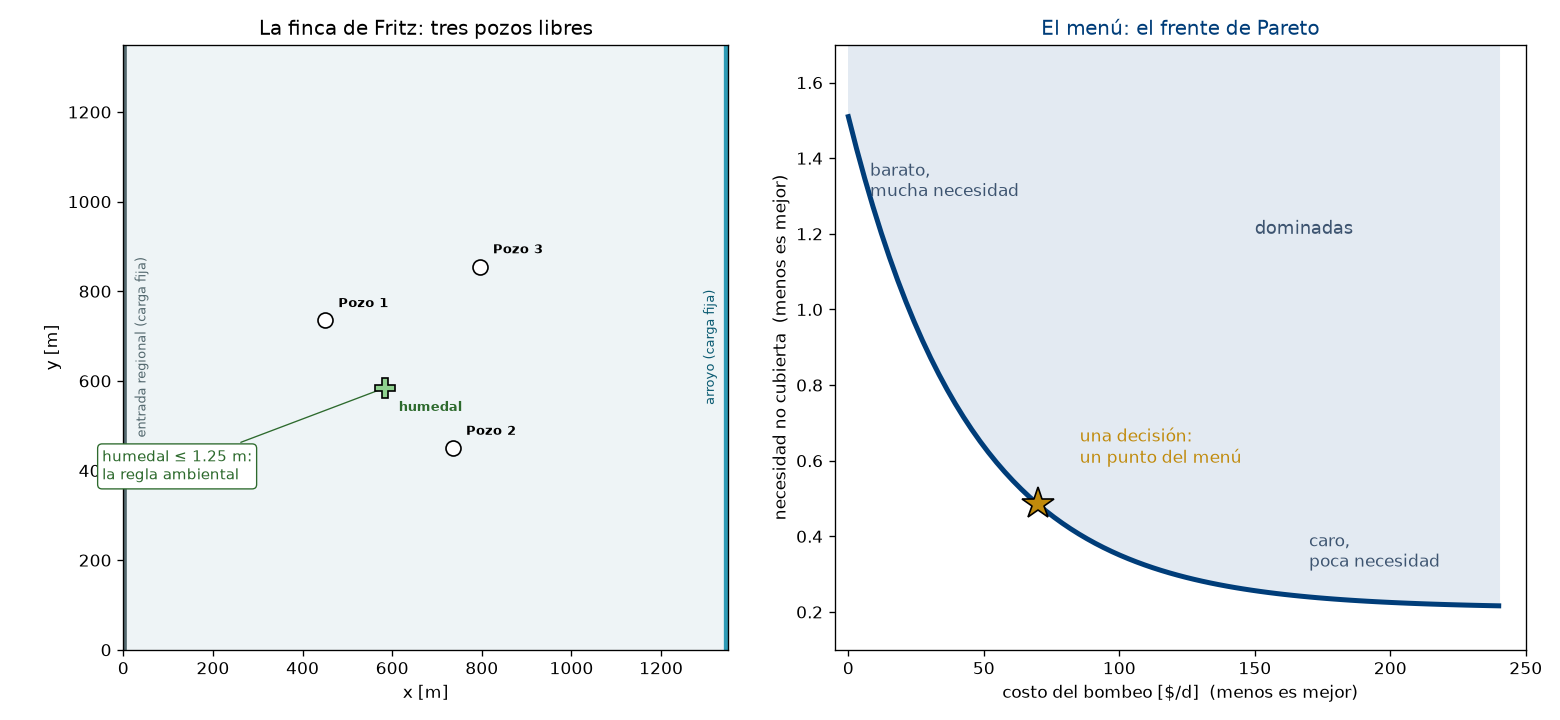

*Izquierda: la finca; los tres pozos se deciden y el humedal es la regla ambiental. Derecha: el frente de Pareto es el menú de compromisos entre costo y necesidad.*

In [ ]:
# Preparación (se ejecuta sola). Si tarda más de un minuto, mira el último paso impreso y díselo al instructor.
import sys, os, glob
print("paso 1 de 5: localizando este cuaderno…", flush=True)
_ruta = os.path.abspath(globals().get("__vsc_ipynb_file__") or next(iter(sorted(glob.glob("Tarea_3*.ipynb"))), "Tarea_3.ipynb"))
print("          ", _ruta, flush=True)
for _modulo, _archivo in (("hidra", "hidra.py"), ("ParOMOPSO_det", os.path.join("pyOMOPSO", "ParOMOPSO_det.py"))):
    try:
        __import__(_modulo)
    except ImportError:                    # hidra.py vive en Curso_Opt; pyOMOPSO en Session_3/Información/codigo: los buscamos subiendo de carpeta
        for _inicio in (os.path.dirname(_ruta), os.getcwd()):
            _d = _inicio
            for _ in range(6):
                _c = next((c for c in (_d, os.path.join(_d, "Información", "codigo")) if os.path.exists(os.path.join(c, _archivo))), None)
                if _c:
                    sys.path.insert(0, os.path.dirname(os.path.join(_c, _archivo))); break
                _d = os.path.dirname(_d)
print("paso 2 de 5: cargando numpy, scipy y matplotlib…", flush=True)
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt
print("paso 3 de 5: cargando hidra y OMOPSO…", flush=True)
import hidra
from ParOMOPSO_det import parOMOPSO_det as OMOPSO_correr
alpha = hidra.matriz_respuesta(); alpha_h = hidra.coeficientes_humedal()
print("paso 4 de 5: cargando otter (las comprobaciones)…", flush=True)
import otter
print("paso 5 de 5: preparando el calificador…", flush=True)
grader = otter.Notebook(_ruta)

C_QP = np.array([0.01, 0.015, 0.02]); GSLEV = np.array([40.0, 40.0, 40.0]); H0 = np.array([34.0, 34.0, 15.0])
C_BASE = np.array([2.0, 1.5, 0.8]); A_IDX = np.array([0.10, 0.20, 0.15]) / 10; K_IDX = 0.5

def evaluar(p):
    # todo lo de una decisión p = (p1, p2, p3): abatimientos, humedal, costo e índice (como en el cuaderno de la sesión)
    p = np.asarray(p, dtype=float); s = alpha @ p
    return {"s": s, "humedal": alpha_h @ p, "costo": np.sum(C_QP * p * (GSLEV - H0 + s)),
            "indice": np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * p)))}

def frente(e_file):
    # el archivo de OMOPSO como dos tablas: F (objetivos) y X (decisiones), una fila por solución
    return np.array([np.ravel(s["cost"]) for s in e_file]), np.array([np.ravel(s["position"]) for s in e_file])
print("Herramientas listas.")

## Etapa 0 · Tus datos (sin puntos)

Escribe el **mismo correo** de las tareas anteriores: identifica tu entrega. Esta tarea usa los mismos datos para todos, los del cuaderno de la sesión.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tu correo de inscripción, entre comillas. El mismo de las tareas anteriores.
IDENTIFICADOR = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
S_HUM, P3 = 1.25, 300.0          # los del cuaderno de la sesión 3 (y de la sesión 1)
print("Entrega de:", IDENTIFICADOR)
print("Los datos son los del cuaderno de la sesión 3, iguales para todos: humedal ≤", S_HUM, "m; para comparar, el pozo 3 de la sesión 1 en", P3, "m³/d.")

In [ ]:
grader.check("q0")

## Etapa 1 · Primero, la herramienta: tu propia función objetivo (1.5 puntos)

**Problema.** Antes de resolver el acuífero, Fritz quiere saber si sabes **usar** OMOPSO (sección 1 del cuaderno, ejemplos 2 y 5). La receta es siempre la misma:
una función que recibe el vector de decisión y devuelve **una columna** de objetivos positivos, el diccionario del problema, los parámetros y `parOMOPSO`.
Lo practicamos con ZDT1, de frente conocido, con cinco variables entre 0 y 1:

$$
f_1 = x_1, \qquad g = 1 + \frac{9}{n-1}\sum_{i=2}^{n} x_i, \qquad f_2 = g\left(1 - \sqrt{f_1 / g}\right)
$$

Su frente verdadero es $f_2 = 1 - \sqrt{f_1}$. La función le suma 0.01 a los dos objetivos para que nunca valgan cero.

**Pregunta.**

1. Escribe la fórmula de $f_2$ como una función de `f1` y `g`: `f2_zdt1 = lambda f1, g: ...` (usa `np.sqrt`).
2. Ejecuta: la celda corre OMOPSO con 25, 50, 100 y 200 iteraciones (40 partículas, misma semilla) y mide la **desviación media** de cada frente a la curva
   verdadera. Escribe `iteraciones_suficientes`: el **menor** número de iteraciones de la tabla con desviación menor que 0.01.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La fórmula de f2 de ZDT1, en función de f1 y g. Sintaxis: lambda f1, g: ...
f2_zdt1 = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def zdt1(x):
    x = np.asarray(x, dtype=float)
    f1 = x[0]
    g = 1 + 9 * np.sum(x[1:]) / (len(x) - 1)
    return np.array([[f1 + 0.01, f2_zdt1(f1, g) + 0.01]]).T          # una columna, objetivos positivos
problema_zdt1 = {"CostFunction": zdt1, "nVar": 5, "VarMin": 0, "VarMax": 1}
parametros_zdt1 = {"MaxIter": 25, "nPop": 40, "w1": 0.1, "w2": 0.5, "e": 0.001, "c1": 1.5, "c2": 2,
                   "nGrid": 7, "alpha": 0.1, "wdamp": 0.99, "r1": 0, "r2": 1, "verbose": 0}
tabla_iter = {}; frentes_iter = {}
print("iteraciones   soluciones   desviación media a la curva verdadera")
for it in [25, 50, 100, 200]:
    np.random.seed(2026)
    ef_z, _, _ = OMOPSO_correr(problema_zdt1, dict(parametros_zdt1, MaxIter=it))
    F_z, _ = frente(ef_z); frentes_iter[it] = F_z
    desv = float(np.mean(np.abs((F_z[:, 1] - 0.01) - (1 - np.sqrt(np.clip(F_z[:, 0] - 0.01, 0, None))))))
    tabla_iter[it] = (len(F_z), desv)
    print(str(it).rjust(8), str(len(F_z)).rjust(12), str(round(desv, 4)).rjust(16))
f1v = np.linspace(0, 1, 200)
fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, it in zip(ejes, [25, 50, 100, 200]):
    ax.plot(f1v + 0.01, 1 - np.sqrt(f1v) + 0.01, "-", color="#003D79", lw=2.5, label="frente verdadero")
    ax.plot(frentes_iter[it][:, 0], frentes_iter[it][:, 1], "o", mfc="#C08A0B", mec="k", ms=5, label="OMOPSO")
    ax.set_title(str(it) + " iteraciones"); ax.set_xlabel("$f_1$"); ax.set_ylim(0, 1.2)
ejes[0].set_ylabel("$f_2$"); ejes[0].legend(); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El menor número de iteraciones de la tabla con desviación media menor que 0.01
iteraciones_suficientes = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Con", iteraciones_suficientes, "iteraciones el frente de OMOPSO ya está sobre la curva verdadera.")

In [ ]:
grader.check("q1")

## Etapa 2 · ¿Cuáles valen la pena? (0.5 puntos)

**Problema.** Fritz tiene cuatro ideas de bombeo. Una idea **domina** a otra si no es peor en ningún objetivo (costo e índice) y es mejor en al menos uno.
Las que no domina nadie son las que valen la pena.

**Pregunta.** Ejecuta, lee la tabla y escribe la lista de ideas **no dominadas** (por ejemplo `["A", "D"]`).

In [ ]:
ideas = {"A": (300, 100, 200), "B": (100, 300, 200), "C": (150, 50, 100), "D": (100, 100, 300)}
F_ideas = {}
print("idea         bombeos       costo [$/d]   índice")
for nombre, p in ideas.items():
    e = evaluar(p); F_ideas[nombre] = np.array([e["costo"], e["indice"]])
    print(nombre.ljust(5), str(p).rjust(16), str(round(e["costo"], 1)).rjust(12), str(round(e["indice"], 3)).rjust(10))

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La lista de ideas no dominadas, con sus letras entre comillas. Ejemplo: ["A", "D"]
no_dominadas = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Según tú, valen la pena:", no_dominadas)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for nombre, f in F_ideas.items():
    elegida = nombre in no_dominadas
    ax.plot(*f, "o", ms=12, mfc="#C08A0B" if elegida else "white", mec="k")
    ax.annotate(nombre, f, xytext=(8, 6), textcoords="offset points", fontsize=12, fontweight="bold")
ax.set_xlabel("costo [$/d]  (menos es mejor)"); ax.set_ylabel("índice de necesidad no cubierta  (menos es mejor)")
ax.set_title("Las cuatro ideas en el espacio de objetivos (oro: las que elegiste)"); plt.tight_layout(); plt.show()

In [ ]:
grader.check("q2")

## Etapa 3 · El menú y cuánto compra cada peso (1 punto)

**Problema.** El frente de **referencia** sale de evaluar una malla de decisiones (los tres bombeos, cada `PASO` m³/d), quedarse con las legales (pozos ≤ 3 m,
humedal ≤ 1.25 m) y marcar las no dominadas: el borde de abajo a la izquierda (sección 2.3 del cuaderno).

**Pregunta.**

1. Escribe el `PASO` de la malla, entre 5 y 25 m³/d (más fino es más exacto y más lento; 10 es un buen valor).
2. Ejecuta. La celda te da el menor índice que se puede lograr gastando como máximo 90 $/d (`I_90`) y como máximo 110 $/d (`I_110`). Escribe la fórmula
   del **precio**: cuánto baja el índice de necesidad no cubierta por cada $/d adicional, alrededor de 100 $/d.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El paso de la malla en m³/d (entre 5 y 25)
PASO = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
g = np.arange(0, 501, PASO)
X_malla = np.array(np.meshgrid(g, g, g, indexing="ij")).reshape(3, -1).T
S_malla = X_malla @ alpha.T
legal = (S_malla <= 3).all(axis=1) & (X_malla @ alpha_h <= S_HUM)
X_leg, S_leg = X_malla[legal], S_malla[legal]
F_leg = np.column_stack([(C_QP * X_leg * (GSLEV - H0 + S_leg)).sum(1), np.exp(-K_IDX * (C_BASE + A_IDX * X_leg)).sum(1)])
orden = np.lexsort((F_leg[:, 1], F_leg[:, 0])); k_ref, mejor = [], np.inf
for i in orden:
    if F_leg[i, 1] < mejor:
        k_ref.append(i); mejor = F_leg[i, 1]
F_ref, X_ref = F_leg[k_ref], X_leg[k_ref]
I_90 = F_ref[F_ref[:, 0] <= 90, 1].min(); I_110 = F_ref[F_ref[:, 0] <= 110, 1].min()
print(len(X_leg), "decisiones legales;", len(F_ref), "en el frente de referencia")
print("menor índice gastando hasta 90 $/d: I_90 =", round(I_90, 4), " | hasta 110 $/d: I_110 =", round(I_110, 4))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(F_leg[::20, 0], F_leg[::20, 1], ".", color="#c9d6e4", ms=3, label="decisiones legales")
ax.plot(F_ref[:, 0], F_ref[:, 1], "-", color="#003D79", lw=2.5, label="tu frente de referencia")
ax.axvline(90, color="#C08A0B", ls=":"); ax.axvline(110, color="#C08A0B", ls=":")
ax.set_xlabel("costo [$/d]"); ax.set_ylabel("índice de necesidad no cubierta"); ax.legend(); ax.set_title("Tu menú de dos objetivos")
plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El precio: cuánto baja el índice por cada $/d adicional entre 90 y 110 $/d (fórmula con I_90 e I_110)
precio = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Alrededor de 100 $/d, cada $/d adicional baja el índice en", round(precio, 5))

In [ ]:
grader.check("q3")

## Etapa 4 · ¿OMOPSO encuentra el mismo menú? (1.5 puntos)

**Problema.** Si no pudiéramos evaluar una malla (un simulador lento, más pozos), solo quedaría OMOPSO. Antes de confiar en él lo medimos contra tu referencia.
OMOPSO no conoce las reglas: la función le suma a cada objetivo un **castigo graduado** $M \cdot v$, donde $v$ es cuánto se violan las reglas (sección 2.4).

**Pregunta.** Elige `MAX_ITER` (iteraciones), `N_POP` (partículas), `E_ARCHIVO` (el ε del archivo) y `M_CASTIGO` (el peso del castigo).
**Regla de Fritz:** como máximo 6 000 movimientos de partícula (iteraciones × partículas), ε entre 0.0001 y 0.05 y $M$ entre 0.1 y 10 000.
La meta: distancia media a tu referencia **por debajo de 1 %** con **al menos 15** soluciones. Si no lo logras, cambia los parámetros y vuelve a ejecutar.
(Pista: recuerda qué pasó en el cuaderno con $M = 1000$.)

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Iteraciones, partículas, el ε del archivo y el peso del castigo. Ejemplo de sintaxis: 50, 30, 0.01 y 5
MAX_ITER = ...
N_POP = ...
E_ARCHIVO = ...
M_CASTIGO = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def fritz_2obj(x):
    e = evaluar(x)
    v = np.maximum(e["s"] - 3, 0).sum() + max(e["humedal"] - S_HUM, 0)
    return np.array([[e["costo"] + M_CASTIGO * v, e["indice"] + M_CASTIGO * v]]).T
parametros = {"MaxIter": MAX_ITER, "nPop": N_POP, "w1": 0.1, "w2": 0.5, "e": E_ARCHIVO, "c1": 1.5, "c2": 2,
              "nGrid": 7, "alpha": 0.1, "wdamp": 0.99, "r1": 0, "r2": 1, "verbose": 0}
np.random.seed(2026)
e_file2, _, _ = OMOPSO_correr({"CostFunction": fritz_2obj, "nVar": 3, "VarMin": 0, "VarMax": 500}, parametros)
F2, X2 = frente(e_file2)
escala = F_ref.max(0) - F_ref.min(0)
distancia = 100 * np.mean([np.min(np.linalg.norm((F_ref - f) / escala, axis=1)) for f in F2])
print("OMOPSO encontró", len(F2), "soluciones; distancia media a tu referencia:", round(distancia, 3), "%",
      "-> META CUMPLIDA" if distancia < 1 and len(F2) >= 15 else "-> todavía no: cambia los parámetros")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(F_ref[:, 0], F_ref[:, 1], "-", color="#003D79", lw=2.5, label="referencia")
ax.plot(F2[:, 0], F2[:, 1], "o", mfc="#C08A0B", mec="k", label="OMOPSO")
ax.set_xlabel("costo [$/d]"); ax.set_ylabel("índice"); ax.legend(); ax.set_title("OMOPSO contra tu referencia")
plt.tight_layout(); plt.show()

In [ ]:
grader.check("q4")

## Etapa 5 · ¿Qué me recomiendas? La solución de compromiso (1 punto)

**Problema.** Para proponer **una** decisión, la celda normaliza cada objetivo de tu menú de la etapa 4 de 0 (lo mejor) a 1 (lo peor) y elige la más cercana
al origen (0, 0), pero **con los pesos que tú le des**: un peso grande hace que ese objetivo cuente más en la distancia.

**Pregunta.**

1. Escribe tus `pesos` para (costo, índice): dos números no negativos que **sumen 1**. Son tu opinión; justifícalos en la etapa 8.
2. Ejecuta, y escribe dos fórmulas: el **bombeo total** de la solución de compromiso (`Z_compromiso`, con los tres bombeos de `p_comp`) y el **número
   del pozo** que más bombea (`pozo_mayor`: 1, 2 o 3).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tus pesos para (costo, índice): no negativos y que sumen 1. Ejemplo: np.array([0.3, 0.7])
pesos = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
F2n = (F2 - F2.min(0)) / (F2.max(0) - F2.min(0))
k_comp = int(np.argmin(np.sqrt(((F2n ** 2) * pesos).sum(axis=1))))
p_comp = X2[k_comp]; e_comp = evaluar(p_comp)
print("Tu solución de compromiso: p =", np.round(p_comp, 1), "m³/d")
print("  costo", round(e_comp["costo"], 1), "$/d | índice", round(e_comp["indice"], 3), "| humedal", round(e_comp["humedal"], 3), "m")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(F_ref[:, 0], F_ref[:, 1], "-", color="#003D79", lw=2, alpha=0.6, label="referencia")
ax1.plot(F2[:, 0], F2[:, 1], "o", mfc="white", mec="k", ms=6, label="tu menú (OMOPSO)")
ax1.plot(*F2[k_comp], "o", color="red", ms=11, label="tu solución de compromiso")
ax1.set_xlabel("costo [$/d]"); ax1.set_ylabel("índice"); ax1.legend(); ax1.set_title("El compromiso sobre tu frente")
hidra.mapa(hidra.simular(p_comp), titulo="Tu solución de compromiso en el acuífero", ax=ax2)
plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El bombeo total de tu solución de compromiso (fórmula con p_comp) y el número del pozo que más bombea (fórmula: 1, 2 o 3)
Z_compromiso = ...
pozo_mayor = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Bombeo total:", round(Z_compromiso, 1), "m³/d | el pozo que más bombea es el", pozo_mayor)

In [ ]:
grader.check("q5")

## Etapa 6 · ¿Y si además cuido el acuífero? Tres objetivos (1.5 puntos)

**Problema.** El problema completo del cuaderno original tiene un tercer objetivo, el **abatimiento total** $S = \sum_i s_i(\mathbf{p})$ (sección 3 del cuaderno).
Con tres objetivos el menú es una cinta curva. Fritz propone una regla sencilla sobre ese menú: el abatimiento total **no más de 5 m**, el índice **no más de
0.6**, y de lo que quede, **lo más barato**. Y quiere compararla con el óptimo de la sesión 1 (pozo 3 fijo en 300 m³/d, el máximo bombeo con el humedal en 1.25 m).

**Pregunta.**

1. Escribe la función del tercer objetivo, `f_abatimiento`: recibe el diccionario `e` de `evaluar` y devuelve el abatimiento total (la suma de `e["s"]`).
2. Escribe los dos límites de la regla: `LIMITE_ABATIMIENTO` (m) y `LIMITE_INDICE`.
3. Ejecuta y escribe dos fórmulas respecto al óptimo de la sesión 1: cuánto **ahorra** Fritz con la elegida (costo del óptimo de la sesión 1 menos costo de la elegida) y cuánta
   **necesidad de más** queda sin cubrir (índice de la elegida menos índice del óptimo de la sesión 1).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El tercer objetivo: una función que recibe e (de evaluar) y devuelve el abatimiento total. Sintaxis: lambda e: ...
f_abatimiento = ...
# Los dos límites de la regla de Fritz: abatimiento total [m] e índice
LIMITE_ABATIMIENTO = ...
LIMITE_INDICE = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def fritz_3obj(x, M=10.0):
    e = evaluar(x)
    v = np.maximum(e["s"] - 3, 0).sum() + max(e["humedal"] - S_HUM, 0)
    return np.array([[f_abatimiento(e) + M * v, e["costo"] + M * v, e["indice"] + M * v]]).T
np.random.seed(2026)
e_file3, _, _ = OMOPSO_correr({"CostFunction": fritz_3obj, "nVar": 3, "VarMin": 0, "VarMax": 500},
                              {"MaxIter": 100, "nPop": 40, "w1": 0.1, "w2": 0.5, "e": 0.001, "c1": 1.5, "c2": 2,
                               "nGrid": 7, "alpha": 0.1, "wdamp": 0.99, "r1": 0, "r2": 1, "verbose": 0})
F3, X3 = frente(e_file3)
cumple = (F3[:, 0] <= LIMITE_ABATIMIENTO) & (F3[:, 2] <= LIMITE_INDICE)
print("menú de", len(F3), "soluciones;", cumple.sum(), "cumplen la regla")
k_el = int(np.flatnonzero(cumple)[np.argmin(F3[cumple, 1])]) if cumple.any() else int(np.argmin(F3[:, 1]))
p_el = X3[k_el]; e_el = evaluar(p_el)
r_t1 = linprog([-1, -1], A_ub=np.vstack([alpha[:, :2], alpha_h[:2]]), b_ub=np.append(3 - alpha[:, 2] * P3, S_HUM - alpha_h[2] * P3),
               bounds=[(0, 1000)] * 2, method="highs")
p_t1 = np.array([r_t1.x[0], r_t1.x[1], P3]); e_t1 = evaluar(p_t1)
print("              bombeos                    abat. total   costo    índice")
print("sesión 1    ", np.round(p_t1, 0), str(round(f_abatimiento(e_t1), 2)).rjust(9), str(round(e_t1["costo"], 1)).rjust(8), str(round(e_t1["indice"], 3)).rjust(8))
print("la elegida  ", np.round(p_el, 0), str(round(f_abatimiento(e_el), 2)).rjust(9), str(round(e_el["costo"], 1)).rjust(8), str(round(e_el["indice"], 3)).rjust(8))
# la superficie de referencia (malla cada 20 m³/d) para ver el menú como en el cuaderno
g3 = np.arange(0, 501, 20.0); Xg = np.array(np.meshgrid(g3, g3, g3, indexing="ij")).reshape(3, -1).T
Sg = Xg @ alpha.T; okg = (Sg <= 3).all(axis=1) & (Xg @ alpha_h <= S_HUM); Xg, Sg = Xg[okg], Sg[okg]
Fg = np.column_stack([Sg.sum(1), (C_QP * Xg * (GSLEV - H0 + Sg)).sum(1), np.exp(-K_IDX * (C_BASE + A_IDX * Xg)).sum(1)])
ndg = np.ones(len(Fg), bool)
for i in range(len(Fg)):
    if ndg[i] and ((Fg <= Fg[i]).all(axis=1) & (Fg < Fg[i]).any(axis=1)).any():
        ndg[i] = False
lo, hi = F3.min(0), F3.max(0)
Fn3 = (F3 - lo) / (hi - lo); Fr3 = (Fg[ndg] - lo) / (hi - lo)
fig = plt.figure(figsize=(10, 8))
for n, azim in enumerate([0, 45, 90, 135]):
    ax = fig.add_subplot(2, 2, n + 1, projection="3d")
    ax.scatter3D(Fr3[:, 0], Fr3[:, 1], Fr3[:, 2], color="#c9d6e4", s=2, alpha=0.4)
    ax.scatter3D(Fn3[:, 0], Fn3[:, 1], Fn3[:, 2], color="white", edgecolors="black", linewidths=0.5)
    ax.scatter3D(*Fn3[k_el], color="red", s=60)
    ax.set_xlabel("Abatimiento"); ax.set_ylabel("Costo"); ax.set_zlabel("Índice"); ax.set_title("Azimut = " + str(azim) + "°")
    ax.view_init(elev=20, azim=azim)
fig.suptitle("Tu menú de tres objetivos (blanco), la referencia (gris) y la elegida (rojo)"); plt.tight_layout(); plt.show()

# La misma figura, interactiva: arrastra para girar, rueda para acercar, doble clic para volver a la vista inicial
fig = hidra.frente_3d((Fr3, "referencia (malla)", "#9fb3c8", 2), (Fn3, "tu menú (OMOPSO)", "white"),
                      ejes=("Abatimiento", "Costo", "Índice"), punto=(Fn3[k_el], "la elegida"),
                      titulo="Tu menú de tres objetivos (blanco), la referencia (gris) y la elegida (rojo)")
fig.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Lo que ahorra Fritz ($/d) y la necesidad de más que queda sin cubrir (índice), respecto al óptimo de la sesión 1 (fórmulas con e_t1 y e_el)
ahorro = ...
necesidad_de_mas = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Fritz ahorra", round(ahorro, 1), "$/d y deja", round(necesidad_de_mas, 3), "de índice más sin cubrir.")
hidra.mapa(hidra.simular(p_el), titulo="La decisión elegida con la regla de Fritz"); plt.show()

In [ ]:
grader.check("q6")

## Etapa 7 · ¿De qué depende cuántas opciones me das? (1 punto)

**Problema.** La autoridad pregunta por qué tu menú de la etapa 4 tiene ese número de soluciones y no otro. Una parte de la respuesta es el **ε del archivo**:
dos soluciones cuyos objetivos caen en la misma «caja» cuentan como una sola (lámina *ε-dominancia*, ejemplo 3 del cuaderno). Un ε grande guarda pocas
soluciones bien repartidas; uno pequeño guarda muchas.

**Pregunta.**

1. Escribe una lista de **tres valores distintos** de ε entre 0.0001 y 0.1. Conviene que estén lejos entre sí: uno pequeño, uno mediano y uno grande.
   La celda corre OMOPSO con cada uno (tu castigo, misma semilla, 60 iteraciones y 30 partículas) y mide cuántas soluciones guarda y qué tan cerca quedan de tu referencia.
2. Lee la tabla y escribe qué ε de tu lista dejó **más soluciones** y cuál quedó **más cerca** de la referencia (la menor distancia).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tres valores distintos de ε, entre 0.0001 y 0.1. Ejemplo de sintaxis: [0.0005, 0.005, 0.05]
EPSILONS = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
tabla_eps = {}; frentes_eps = {}
print("   ε         soluciones   distancia a la referencia")
for eps in EPSILONS:
    np.random.seed(2026)
    ef, _, _ = OMOPSO_correr({"CostFunction": fritz_2obj, "nVar": 3, "VarMin": 0, "VarMax": 500}, dict(parametros, MaxIter=60, nPop=30, e=eps))
    Fe, _ = frente(ef); frentes_eps[eps] = Fe
    d_eps = 100 * np.mean([np.min(np.linalg.norm((F_ref - f) / escala, axis=1)) for f in Fe])
    tabla_eps[eps] = (len(Fe), d_eps)
    print(str(eps).rjust(8), str(len(Fe)).rjust(12), str(round(d_eps, 3)).rjust(16), "%")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(F_ref[:, 0], F_ref[:, 1], "-", color="#003D79", lw=2.5, label="referencia")
for eps, marca in zip(EPSILONS, ["o", "s", "^"]):
    Fe = frentes_eps[eps]; ax.plot(Fe[:, 0], Fe[:, 1], marca, ms=6, alpha=0.75, label="ε = " + str(eps) + " (" + str(len(Fe)) + ")")
ax.set_xlabel("costo [$/d]"); ax.set_ylabel("índice"); ax.legend(); ax.set_title("El mismo enjambre con tres ε del archivo")
plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El ε de tu lista que dejó MÁS soluciones y el que quedó MÁS CERCA de la referencia (dos números de tu lista)
eps_mas_soluciones = ...
eps_mas_cerca = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("más soluciones con ε =", eps_mas_soluciones, "| más cerca de la referencia con ε =", eps_mas_cerca)

In [ ]:
grader.check("q7")

## Etapa 8 · El informe para la autoridad y para Fritz (2 puntos, los leo yo)

Responde en las celdas de texto, entre tres y cinco líneas cada una, con **tus** números.

<!-- BEGIN QUESTION -->

**8a.** Para Fritz: ¿qué le dice el frente de la etapa 3? Usa tu precio (cuánto baja la necesidad no cubierta por cada $/d) y explica qué significa que el frente sea una curva y no una recta a la hora de decidir cuánto gastar.

<!-- RESPUESTA:q8a -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**8b.** ¿Por qué elegiste esos pesos en la etapa 5? ¿Qué pasaría con la solución de compromiso si le dieras todo el peso al índice? ¿Quién debería elegir los pesos?

<!-- RESPUESTA:q8b -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**8c.** Compara la decisión de la regla de Fritz (etapa 6) con el óptimo de la sesión 1 (807 m³/d con los datos del cuaderno): ¿cuánto ahorra, cuánta necesidad deja sin cubrir y vale la pena? ¿Qué agregó el tercer objetivo, el abatimiento total?

<!-- RESPUESTA:q8c -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

---
### Antes de entregar

1. Menú **Ejecutar todo** (Run All): el cuaderno debe correr de principio a fin sin errores. Tarda unos dos minutos.
2. Revisa que cada `grader.check` muestre sus pruebas visibles en verde.
3. Guarda el archivo como `Tarea_3_<tu nombre>.ipynb` y súbelo al formulario del curso antes del 24 de noviembre.